# Part 2: ViT from scratch

This is the local + global input study. Earlier outputs are kept in archive/full_photo_v10.
Build the new soil-cv-utils ZIP and upload it as a new code dataset version first.
Attach that version and the soil competition data. Version 10 has the older code.
Use Internet, 2 x T4 and the WANDB_API_KEY secret. Then Save & Run All.
All new files stay in /kaggle/working. No CV-summary run or competition submission is made.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["SOILCV_VIT_FAMILY"] = "scratch"
os.environ["SOILCV_VIT_OUTPUT_DIR"] = "/kaggle/working/part2_scratch_multiscale"
os.environ["TORCH_HOME"] = "/tmp/soilcv-torch"
os.environ["WANDB_CACHE_DIR"] = "/tmp/soilcv-wandb-cache"
code_root = Path("/kaggle/input/datasets/denysmykhailov/soil-cv-utils")
if not (code_root / "soilcv/vit/model.py").is_file():
    matches = list(Path("/kaggle/input").rglob("soilcv/vit/model.py"))
    if len(matches) != 1:
        raise RuntimeError("Attach the new soil-cv-utils code dataset.")
    code_root = matches[0].parents[2]
sys.path.insert(0, str(code_root))
os.environ["PYTHONPATH"] = (
    str(code_root) + os.pathsep + os.environ.get("PYTHONPATH", "")
)
from soilcv.artifacts import package_identity

if (
    package_identity()["source_hash"]
    != "4b60a00c640d9f745f30841d63291ccc5b5cbd61be6232d2bd803798c2d2aeac"
):
    raise RuntimeError(
        "Update the code dataset with the new ZIP and select that version."
    )
from kaggle_secrets import UserSecretsClient

os.environ["WANDB_API_KEY"] = UserSecretsClient().get_secret("WANDB_API_KEY")

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

from soilcv.cnn.outputs import save_source
from soilcv.vit.analysis import collect_results, plot_learning, plot_scores
from soilcv.vit.experiments import RECIPES, ROOT, jobs, prepare
from soilcv.vit.outputs import export_outputs

if torch.cuda.device_count() != 2:
    raise RuntimeError("Select 2 x T4 GPUs.")
print("GPUs:", [torch.cuda.get_device_name(i) for i in range(2)])
print("Code:", package_identity())
print("New output folder:", ROOT)

GPUs: ['Tesla T4', 'Tesla T4']
Code: {'version': '0.1.1', 'source_hash': '4b60a00c640d9f745f30841d63291ccc5b5cbd61be6232d2bd803798c2d2aeac', 'folds_hash': '057fe8f93ba35d2ab7a3483063c95ca0079c4bcbb9978671c16ffc4119d9c1b2'}
New output folder: /kaggle/working/part2_scratch_multiscale


## Local detail and global context

All 64 mm tiles at 288 px give about 4.5 px/mm for local detail.
A full photo at 2 px/mm gives context. It is not the only input any more.
The same encoder reads both views. We join their features before the curve head.
All tiles and photos are used. Tile overlap has area weights. Photos have equal weights.
One soil gets one curve and one EMD loss.

Both views still resize the source. Local tiles keep more detail than the global view.
We do not claim to keep all native iPhone detail. PPM still assumes no source crop.

In [2]:
metadata = prepare()
save_source(ROOT)
geometry = pd.read_csv(ROOT / "image_geometry.csv")
tile_coverage = pd.read_csv(ROOT / "tile_spatial_coverage.csv")
assert geometry.spatial_coverage.eq(1).all()
assert geometry.cropped_source_area.eq(0).all()
assert tile_coverage.spatial_coverage.eq(1).all()
print("Study:", metadata["run_id"])
print("Hypotheses commit:", metadata["identity"]["hypotheses_commit"])
print("Spatial coverage measures area, not saved image detail.")
display(
    geometry.groupby("device")[
        ["actual_ppm_x", "linear_scale_ratio", "pixel_count_ratio"]
    ].agg(["min", "max"])
)
display(
    tile_coverage.groupby("device")[
        ["local_ppm", "linear_scale_ratio", "pixel_count_ratio"]
    ].agg(["min", "max"])
)

Study: scratch | photos: 162 | max patch-16 tokens: 1452
Study: 20261101T183703Z-38390ab494
Hypotheses commit: a39b8a5
Spatial coverage measures area, not saved image detail.


actual_ppm_x           linear_scale_ratio            \
                                 min       max                min       max   
device                                                                        
Motorola Edge               1.998331  1.999608           0.435085  0.435085   
Motorola Edge 60 Fusion     1.999391  2.001758           0.160449  0.160449   
Samsung A52                 1.999291  1.999291           0.439180  0.439180   
iPhone 14                   1.998630  2.000935           0.143451  0.143451   
iPhone 16                   1.999672  2.000811           0.102433  0.102433   

                        pixel_count_ratio            
                                      min       max  
device                                               
Motorola Edge                    0.189104  0.189104  
Motorola Edge 60 Fusion          0.025759  0.025759  
Samsung A52                      0.192805  0.192805  
iPhone 14                        0.020574  0.020574  
iPhone 16                        0.010495  0.010495

local_ppm      linear_scale_ratio            \
                              min  max                min       max   
device                                                                
Motorola Edge                 4.5  4.5           0.979592  0.979592   
Motorola Edge 60 Fusion       4.5  4.5           0.360902  0.360902   
Samsung A52                   4.5  4.5           0.989691  0.989691   
iPhone 14                     4.5  4.5           0.322870  0.322870   
iPhone 16                     4.5  4.5           0.230400  0.230400   

                        pixel_count_ratio            
                                      min       max  
device                                               
Motorola Edge                    0.959600  0.959600  
Motorola Edge 60 Fusion          0.130250  0.130250  
Samsung A52                      0.979488  0.979488  
iPhone 14                        0.104245  0.104245  
iPhone 16                        0.053084  0.053084

## Scratch ViT

Use the Lecture 1 design: patch embedding, CLS, attention blocks and MLPs.
2-D sine/cosine positions work with different shapes. Each view has its own CLS features.
We test patch 16, patch 32 and no warmup. Weights start at random.
Padding repeats edge pixels. Attention reduces the weight of partial patches
and masks fully padded tokens. A partial patch can still change near the border.

In [3]:
columns = [
    "id",
    "view_mode",
    "arch",
    "pixels",
    "target_ppm",
    "schedule",
    "warmup",
    "epochs",
    "patience",
]
display(pd.DataFrame(RECIPES)[columns])
hypotheses = (code_root / "HYPOTHESES.md").read_text()
marker = "# Part 2 revision: local detail and global context"
print(marker + hypotheses.split(marker, 1)[1])
print("Standard fold jobs:", 4 * len(RECIPES))
print("Camera diagnostic jobs:", len(jobs()) - 4 * len(RECIPES))

,id,view_mode,arch,pixels,target_ppm,schedule,warmup,epochs,patience
0,vit-scratch-p16,multiscale,scratch_vit,288,2.0,warmup_cosine,3,32,7
1,vit-scratch-p32,multiscale,scratch_vit,288,2.0,warmup_cosine,3,32,7
2,vit-scratch-no-warmup,multiscale,scratch_vit,288,2.0,warmup_cosine,0,32,7


# Part 2 revision: local detail and global context

This plan replaces the full-photo-only input and Pareto checkpoint rule above.
Keep the old plan and all earlier results as a record. Do not retrain CNNs.
Keep the same four soil folds and seed 42 + fold.

Each photo now has two views. All 64 mm grid tiles at 288 px give local detail
at about 4.5 px/mm. The full photo at 2 px/mm gives global context only.
Both views use the same encoder. Pool local features with overlap-area weights,
join local and global features, then average photos before one curve head.
Do not call the global view a high-detail image. Local tiles also do not keep
all native iPhone detail. They keep the physical scale used by the CNN study.

| ID | Comparison | Prediction before training |
| --- | --- | --- |
| H-VIT2-01 | Local + global vs the earlier full-photo-only plan | Local inputs may keep grain texture that 2 px/mm removed. Context may help large structures. This is a new input experiment, not proof that Vi

## Train and save checkpoints

The four sample folds stay the same. Each GPU runs one fold.
Best checkpoint and early stopping use validation EMD only, from epoch one.
Camera disagreement is a separate W&B diagnostic. It cannot block a better EMD epoch.

Save the top three epochs by EMD. Predict with ranks one and two.
Also use rank three only if its camera disagreement is lower than rank two.
Use these same weights for OOF and test. Show best-only CV next to this epoch ensemble.
This rule still uses validation data for a choice. CV can be optimistic.

Camera jobs train on one camera and score both cameras on paired new soils.
They use the same folds. Field of view and foreground changes are left for SSL.

In [4]:
subprocess.run([sys.executable, "-m", "soilcv.vit.launcher"], check=True)
status = json.loads((ROOT / "status.json").read_text())
assert len(status["jobs"]) == len(jobs())
assert all(job["state"] == "complete" for job in status["jobs"])
print("Complete fold jobs:", len(status["jobs"]))

started vit-scratch-p16 0 None GPU 0
started vit-scratch-p16 1 None GPU 1
complete vit-scratch-p16 0 None
started vit-scratch-p16 2 None GPU 0
complete vit-scratch-p16 1 None
started vit-scratch-p16 3 None GPU 1
complete vit-scratch-p16 2 None
started vit-scratch-p32 0 None GPU 0
complete vit-scratch-p16 3 None
started vit-scratch-p32 1 None GPU 1
complete vit-scratch-p32 0 None
started vit-scratch-p32 2 None GPU 0
complete vit-scratch-p32 1 None
started vit-scratch-p32 3 None GPU 1
complete vit-scratch-p32 2 None
started vit-scratch-no-warmup 0 None GPU 0
complete vit-scratch-no-warmup 0 None
started vit-scratch-no-warmup 1 None GPU 0
complete vit-scratch-p32 3 None
started vit-scratch-no-warmup 2 None GPU 1
complete vit-scratch-no-warmup 1 None
started vit-scratch-no-warmup 3 None GPU 0
complete vit-scratch-no-warmup 2 None
started vit-scratch-p16 0 Motorola GPU 1
complete vit-scratch-p16 0 Motorola
started vit-scratch-p16 1 Motorola GPU 1
complete vit-scratch-p16 1 Motorola
started 

## Results and checks

Each test CSV averages four folds of one recipe.
Inside each fold it uses the selected two or three epochs.
Camera diagnostic runs stay out of the main recipe ranking.
A reload check must match all ten test soils. Padding checks do not change checkpoint choice.

,experiment,run_id,arch,view_mode,local_ppm,context_ppm,cv_emd,fold_mean,fold_std,best_only_cv_emd,...,camera_paired_samples,motorola_emd,samsung_emd,camera_disagreement,gpu_hours,peak_gpu_mb,epochs_per_fold,best_epochs,public_lb,private_lb
0,vit-scratch-p32,20261101T183703Z-38390ab494,scratch_vit,multiscale,4.5,2.0,33.918,33.918,11.833,31.945,...,21,36.563,51.241,40.658,1.151,521.238,"14,20,14,26","6,12,6,18",not submitted,not available
1,vit-scratch-no-warmup,20261101T183703Z-38390ab494,scratch_vit,multiscale,4.5,2.0,34.887,34.887,9.164,35.331,...,21,40.334,44.583,39.531,1.153,510.300,"12,19,11,32","4,11,3,31",not submitted,not available
2,vit-scratch-p16,20261101T183703Z-38390ab494,scratch_vit,multiscale,4.5,2.0,39.520,39.520,22.677,40.332,...,21,46.374,52.795,33.764,1.233,510.300,"12,13,23,31","4,5,15,23",not submitted,not available


,experiment,run_id,train_camera,domain_paired_samples,e_same,e_cross,delta_domain,camera_disagreement,gpu_hours,peak_gpu_mb
0,vit-scratch-p16,20261101T183703Z-38390ab494,Motorola,21,37.955,37.832,-0.123,30.942,0.690,469.986
1,vit-scratch-p16,20261101T183703Z-38390ab494,Samsung,21,52.887,48.454,-4.433,18.789,0.609,470.361


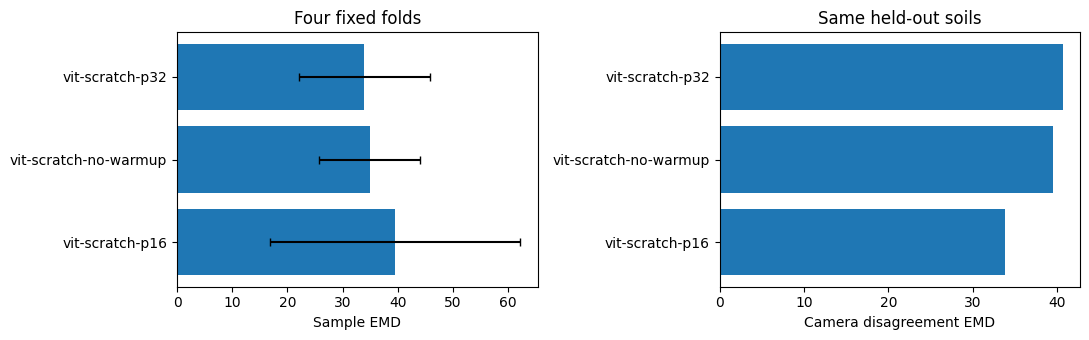

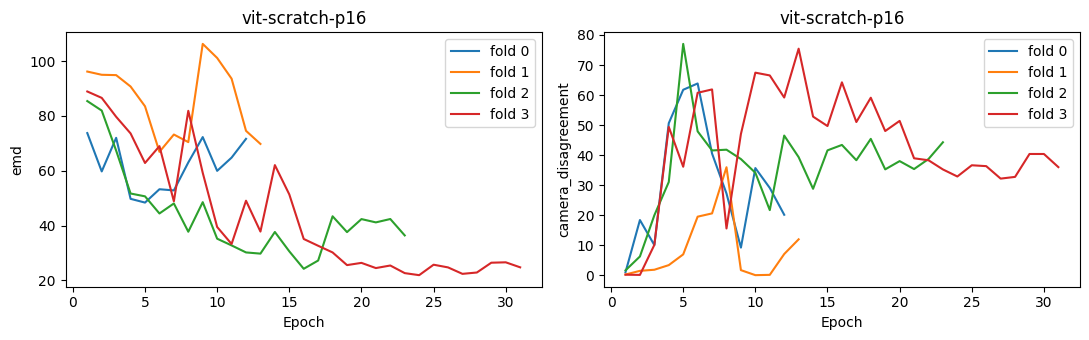

,experiment,fold,checked_samples,padding_mean_emd,padding_max_emd,padding_samples,padding_extra_pixels
0,vit-scratch-p16,0,F827,0.0000,0.0000,1,16
1,vit-scratch-p16,1,H371,0.0000,0.0000,1,16
2,vit-scratch-p16,2,H030,0.0000,0.0000,1,16
3,vit-scratch-p16,3,H181,0.0001,0.0001,1,16
4,vit-scratch-p32,0,F827,0.0000,0.0000,1,32
5,vit-scratch-p32,1,H371,0.0000,0.0000,1,32
6,vit-scratch-p32,2,H030,0.0000,0.0000,1,32
7,vit-scratch-p32,3,H181,0.0000,0.0000,1,32
8,vit-scratch-no-warmup,0,F827,0.0000,0.0000,1,16
9,vit-scratch-no-warmup,1,H371,0.0000,0.0000,1,16


# ViT results

Run ID: `20261101T183703Z-38390ab494`.
Code hash: `4b60a00c640d9f745f30841d63291ccc5b5cbd61be6232d2bd803798c2d2aeac`.

The same four sample folds are used for every model. Lower EMD is better.
Each test CSV is the mean of four folds of the same recipe.
Each fold averages its top two validation EMD epochs. Rank three joins only if its camera disagreement is lower than rank two.
The OOF curve uses the exact same selected epochs as test inference.

| Recipe | Input | Epoch ensemble EMD | Best-only EMD | Fold std | Camera disagreement | GPU hours |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| vit-scratch-p32 | multiscale | 33.918 | 31.945 | 11.833 | 40.658 | 1.151 |
| vit-scratch-no-warmup | multiscale | 34.887 | 35.331 | 9.164 | 39.531 | 1.153 |
| vit-scratch-p16 | multiscale | 39.520 | 40.332 | 22.677 | 33.764 | 1.233 |

The best standard OOF recipe is vit-scratch-p32.
Camera gap means EMD between Motorola and Samsung predictions for the same held-out soil.
It is not

In [5]:
results, oof_predictions, camera_domains = collect_results()
display(results.round(3))
display(camera_domains.round(3))
figure = plot_scores(results)
figure.savefig(ROOT / "results/scores.png", dpi=150)
plt.show()
figure = plot_learning()
figure.savefig(ROOT / "results/learning.png", dpi=150)
plt.show()
padding_checks = pd.read_csv(ROOT / "results/padding_checks.csv")
display(padding_checks.round(4))
print((ROOT / "VIT_RESULTS.md").read_text())

## Kaggle Outputs

Keep all top-three weight files, candidate rules, OOF curves, test CSVs and checks.
Large optimizer snapshots are kept during training. They are removed after that fold succeeds.
Earlier studies use other folders and are not changed.
Source code, environment and logs are saved too. The best recipe gives submission.csv.
results/inference_ensembles.json has the exact four-fold W&B groups.
The data has only 24 soils. Fold std is not a confidence interval.

In [6]:
folder = export_outputs()
submission = pd.read_csv(ROOT.parent / "submission.csv")
display(submission.head())
print("Submission shape:", submission.shape)
print("Study files:", folder)
print("W&B: https://wandb.ai/public-team/soil-grain-size")

Saved study: /kaggle/working/part2_scratch_multiscale | top-level submission: /kaggle/working/submission.csv


,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,HPC_Airbus BS6-3,2.500313,5.347436,16.148987,44.577273,77.864492,85.860551,88.819081,93.491642,97.962289,99.834376,100.0
1,HPC_Audorfring,2.616855,5.511516,14.696699,38.185221,66.487741,77.946998,82.535521,90.194703,96.986947,99.773886,100.0
2,HPC_Muenster_BS6_9_0-10m,0.892487,1.846980,4.005611,7.911811,11.927524,16.633388,30.614688,58.092837,88.364884,99.501811,100.0
3,HPC_Airbus BS10-4bis7,2.620142,5.573723,16.494085,45.559387,79.391600,87.430747,90.057151,94.190414,98.169856,99.843569,100.0
4,HPC_Airbus BS12-5bis8,2.640916,5.598768,16.751300,46.087158,79.644330,87.878309,90.447105,94.466921,98.250242,99.846618,100.0


Submission shape: (10, 12)
Study files: /kaggle/working/part2_scratch_multiscale
W&B: https://wandb.ai/public-team/soil-grain-size
